# Disaster Social Media Sentiment Analysis with Hugging Face


## Learning objectives
By the end of this session, you will be able to:
1. Explain what a pretrained transformer sentiment model does.
2. Run Hugging Face sentiment analysis on multiple social media posts.
3. Interpret labels and confidence scores in a pandas DataFrame.
4. Summarize sentiment distributions.
5. Recognize important limitations when applying general sentiment models to disaster response.


## 1. Set up the environment

For this Jupyter notebook, we created a ModuLair virtual environment `hf_env` in our personal scratch space by following the instructions on the slide. 

# <span style="color:red">⚠️ Note: Do NOT use `geo_ai_env` for this notebook!</span>


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from transformers import pipeline

print("pandas:", pd.__version__)
print("Imports successful!")
print(plt)

pandas: 3.0.6
Imports successful!
<module 'matplotlib.pyplot' from '/scratch/user/u.zh108696/virtual_envs/hf_env/lib/python3.12/site-packages/matplotlib/pyplot.py'>


## 2. Load a pretrained Hugging Face model

We will use `distilbert/distilbert-base-uncased-finetuned-sst-2-english`, a DistilBERT model fine-tuned for **binary sentiment classification**.

- `POSITIVE`: the model considers the text positive.
- `NEGATIVE`: the model considers the text negative.
- `score`: the model's confidence score for its selected label.

This is a general-purpose sentiment model, not a disaster-specific model. It does not directly classify emergency needs or determine whether someone requires rescue.

The first run downloads model files from Hugging Face, so internet access may be required unless the model is already cached.


In [2]:
model_name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

classifier = pipeline(
    task="sentiment-analysis",
    model=model_name
)

print("Model loaded:", model_name)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded: distilbert/distilbert-base-uncased-finetuned-sst-2-english


## 3. Prepare sample social media posts

These examples are fictional and designed for learning. Real-world social media data can contain personal information, misinformation, spam, and unverified reports.


In [3]:
posts = [
    "The hurricane destroyed our homes. We need help!",
    "Thank you to all the volunteers rescuing families.",
    "Flooding is getting worse. We are trapped on the roof.",
    "The community is working together to rebuild.",
    "I lost everything in the wildfire. I feel hopeless.",
    "Emergency shelters are providing food and water."
]

for i, post in enumerate(posts, start=1):
    print(f"{i}. {post}")

1. The hurricane destroyed our homes. We need help!
2. Thank you to all the volunteers rescuing families.
3. Flooding is getting worse. We are trapped on the roof.
4. The community is working together to rebuild.
5. I lost everything in the wildfire. I feel hopeless.
6. Emergency shelters are providing food and water.


## 4. Run sentiment analysis

The `pipeline()` accepts a list of strings, so we can process multiple posts in one call. `batch_size=4` asks the pipeline to process inputs in batches of up to four.

The model returns a list of dictionaries, one for each input.


In [4]:
results = classifier(posts, batch_size=4)

print("First prediction:")
print(results[0])

print("\nAll predictions:")
for post, result in zip(posts, results):
    print(f"{result['label']:8s} ({result['score']:.3f})  {post}")

First prediction:
{'label': 'NEGATIVE', 'score': 0.997485876083374}

All predictions:
NEGATIVE (0.997)  The hurricane destroyed our homes. We need help!
POSITIVE (1.000)  Thank you to all the volunteers rescuing families.
NEGATIVE (0.999)  Flooding is getting worse. We are trapped on the roof.
POSITIVE (0.992)  The community is working together to rebuild.
NEGATIVE (1.000)  I lost everything in the wildfire. I feel hopeless.
POSITIVE (0.560)  Emergency shelters are providing food and water.


### Understand the output

A prediction looks like this:

```python
{"label": "NEGATIVE", "score": 0.99}
```

The exact values depend on the model output. The score is the model's score for its chosen class. It is **not** a measure of how urgent a request is, whether a claim is true, or how severe a disaster is.


## 5. Put predictions into a pandas DataFrame

A DataFrame makes it easier to inspect, filter, export, and summarize predictions.


In [5]:
df = pd.DataFrame({
    "post": posts,
    "sentiment": [result["label"] for result in results],
    "confidence": [round(result["score"], 4) for result in results]
})

df

,post,sentiment,confidence
0,The hurricane destroyed our homes. We need help!,NEGATIVE,0.9975
1,Thank you to all the volunteers rescuing famil...,POSITIVE,0.9998
2,Flooding is getting worse. We are trapped on t...,NEGATIVE,0.9994
3,The community is working together to rebuild.,POSITIVE,0.9918
4,I lost everything in the wildfire. I feel hope...,NEGATIVE,0.9997
5,Emergency shelters are providing food and water.,POSITIVE,0.5604


### Explore the results

Try these operations:
- `df.head()` displays the first rows.
- `df["sentiment"].value_counts()` counts each label.
- `df.sort_values("confidence")` sorts by confidence.


In [6]:
print("First rows:")
display(df.head())

print("Sentiment counts:")
display(df["sentiment"].value_counts().rename_axis("sentiment").to_frame("count"))

print("Lowest-confidence predictions first:")
display(df.sort_values("confidence", ascending=True))

First rows:


,post,sentiment,confidence
0,The hurricane destroyed our homes. We need help!,NEGATIVE,0.9975
1,Thank you to all the volunteers rescuing famil...,POSITIVE,0.9998
2,Flooding is getting worse. We are trapped on t...,NEGATIVE,0.9994
3,The community is working together to rebuild.,POSITIVE,0.9918
4,I lost everything in the wildfire. I feel hope...,NEGATIVE,0.9997


Sentiment counts:


,count
sentiment,
NEGATIVE,3
POSITIVE,3


Lowest-confidence predictions first:


,post,sentiment,confidence
5,Emergency shelters are providing food and water.,POSITIVE,0.5604
3,The community is working together to rebuild.,POSITIVE,0.9918
0,The hurricane destroyed our homes. We need help!,NEGATIVE,0.9975
2,Flooding is getting worse. We are trapped on t...,NEGATIVE,0.9994
4,I lost everything in the wildfire. I feel hope...,NEGATIVE,0.9997
1,Thank you to all the volunteers rescuing famil...,POSITIVE,0.9998


## 6. Summarize sentiment

Counts show how many posts received each label. Percentages help compare datasets of different sizes.

Remember that these summaries describe the model's predictions on this sample; they do not necessarily represent the emotions of an entire affected population.


In [7]:
sentiment_counts = df["sentiment"].value_counts()
sentiment_percentages = (
    df["sentiment"].value_counts(normalize=True).mul(100).round(1)
)

print("Sentiment distribution:")
print(sentiment_counts)

print("\nSentiment percentages:")
print(sentiment_percentages)

Sentiment distribution:
sentiment
NEGATIVE    3
POSITIVE    3
Name: count, dtype: int64

Sentiment percentages:
sentiment
NEGATIVE    50.0
POSITIVE    50.0
Name: proportion, dtype: float64


## 7. Visualize the sentiment distribution

A bar chart provides a quick overview of the labels assigned by the model.


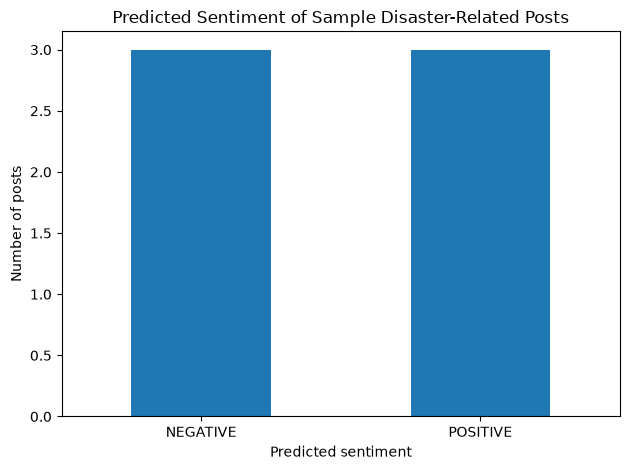

In [8]:
sentiment_counts.plot(kind="bar")
plt.title("Predicted Sentiment of Sample Disaster-Related Posts")
plt.xlabel("Predicted sentiment")
plt.ylabel("Number of posts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Hands-on exercises

Try each exercise before looking at the solutions below.


### Exercise 1 — Add new posts

Add at least three fictional posts, including:
- one expressing fear or distress;
- one thanking responders;
- one asking for a resource such as water, shelter, or medicine.

Run the classifier on the new posts and compare the labels.

**Starter code:**
```python
new_posts = [
    # Add your examples here
]

new_results = classifier(new_posts)
```


In [9]:
# Exercise 1: Add your own examples and run this cell.
new_posts = [
    "We need clean drinking water at the shelter.",
    "I am grateful that our neighbors brought supplies.",
    "I am frightened because the fire is getting closer."
]

new_results = classifier(new_posts)

new_df = pd.DataFrame({
    "post": new_posts,
    "sentiment": [r["label"] for r in new_results],
    "confidence": [round(r["score"], 4) for r in new_results]
})

new_df

,post,sentiment,confidence
0,We need clean drinking water at the shelter.,NEGATIVE,0.9988
1,I am grateful that our neighbors brought suppl...,POSITIVE,0.9991
2,I am frightened because the fire is getting cl...,NEGATIVE,0.9227


### Exercise 2 — Filter negative posts

Use pandas to display only posts predicted as `NEGATIVE`.

**Hint:** Boolean filtering looks like `df[df["column"] == value]`.


In [10]:
# Exercise 2
negative_posts = df[df["sentiment"] == "NEGATIVE"]
negative_posts

,post,sentiment,confidence
0,The hurricane destroyed our homes. We need help!,NEGATIVE,0.9975
2,Flooding is getting worse. We are trapped on t...,NEGATIVE,0.9994
4,I lost everything in the wildfire. I feel hope...,NEGATIVE,0.9997


### Exercise 3 — Find high-confidence predictions

Display posts whose confidence score is greater than 0.90.

Discuss: Does a high score guarantee that the prediction is correct or useful for emergency operations?


In [11]:
# Exercise 3
high_confidence_posts = df[df["confidence"] > 0.90]
high_confidence_posts

,post,sentiment,confidence
0,The hurricane destroyed our homes. We need help!,NEGATIVE,0.9975
1,Thank you to all the volunteers rescuing famil...,POSITIVE,0.9998
2,Flooding is getting worse. We are trapped on t...,NEGATIVE,0.9994
3,The community is working together to rebuild.,POSITIVE,0.9918
4,I lost everything in the wildfire. I feel hope...,NEGATIVE,0.9997


## 9. Export results

In a research workflow, you may want to save predictions for further analysis. This writes a CSV file to the current working directory.


In [12]:
output_file = "disaster_sentiment_predictions.csv"
df.to_csv(output_file, index=False)
print(f"Saved predictions to: {output_file}")

Saved predictions to: disaster_sentiment_predictions.csv


## 10. Wrap-up and discussion

### Key takeaways
- Hugging Face `pipeline()` makes it easy to apply a pretrained model to text.
- pandas helps organize, filter, summarize, and export predictions.
- Visualization makes the output easier to interpret.
- A general sentiment model is a starting point—not a complete disaster-response intelligence system.

### Further reading
- [Hugging Face Transformers pipelines](https://huggingface.co/docs/transformers/en/main_classes/pipelines)
- [Model card: DistilBERT SST-2 sentiment analysis](https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english)
